# Temporal Relation Extraction with Syntax-Guided Graph Transformers


In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from evaluate_bert import load_model,evaluate
from train_bert import MatresDataset
from evaluate_sgt import load_model as load_sgt_model
from evaluate_sgt import evaluate as evaluate_sgt
from train_sgt import SGTDataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,ConfusionMatrixDisplay,f1_score
from dependency_garph import build_dependency_graph,get_dependency_path,nlp
from sequence_encoder import align_event_to_spacy
from spacy import displacy


## 1. MATRES Dataset Exploration

MATRES is a dataset for temporal relation classification.
Each example contains a pair of events and their annotated
temporal relationship: BEFORE, AFTER, EQUAL, or VAGUE.

In [6]:
train_df = pd.read_csv("processed_data/train.csv")
val_df = pd.read_csv("processed_data/val.csv")
test_df = pd.read_csv("processed_data/test.csv")

print("MATRES Dataset")
print(f"Training examples:   {len(train_df)}")
print(f"Validation examples: {len(val_df)}")
print(f"Test examples:       {len(test_df)}")

MATRES Dataset
Training examples:   11890
Validation examples: 850
Test examples:       837


In [7]:
train_df.head()

,doc_id,text,event1,event2,event1_index,event2_index,relation,label,sent_diff
0,ABC19980120.1830.0957,People have predicted his demise so many times...,predicted,tried,2,13,BEFORE,0,0
1,ABC19980120.1830.0957,People have predicted his demise so many times...,predicted,hasten,2,15,BEFORE,0,0
2,ABC19980120.1830.0957,People have predicted his demise so many times...,tried,hasten,13,15,VAGUE,3,0
3,ABC19980120.1830.0957,He has outlasted and sometimes outsmarted eigh...,outlasted,outsmarted,2,5,VAGUE,3,0
4,ABC19980120.1830.0957,Fidel Castro invited John Paul to come for a r...,invited,come,2,6,BEFORE,0,0


In [8]:
example = train_df.iloc[0]
print("Text:", example["text"])

Text: People have predicted his demise so many times , and the US has tried to hasten it on several occasions .


## 2. Class Distribution in MATRES

The MATRES dataset contains four temporal relation classes: BEFORE, AFTER, EQUAL, and VAGUE. We are examining the training data to identify class imbalance.


In [9]:
labels = ["BEFORE", "AFTER", "EQUAL", "VAGUE"]
counts = []
for i,label in enumerate(labels):
    count = (train_df["label"] == i).sum()
    counts.append(count)   
    print(label, ":", count)

BEFORE : 5984
AFTER : 4216
EQUAL : 395
VAGUE : 1295


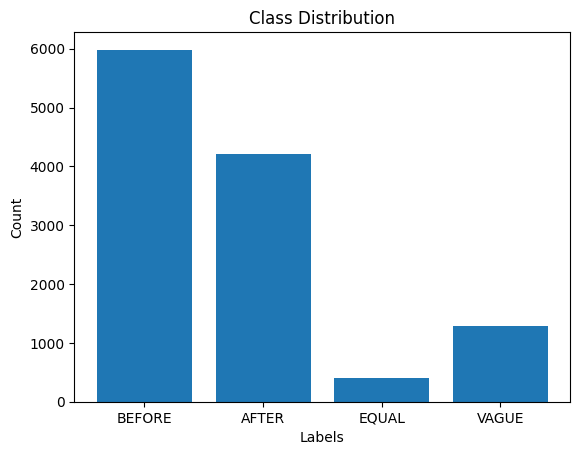

In [10]:
plt.bar(labels,counts)
plt.title("Class Distribution")
plt.xlabel("Labels")
plt.ylabel("Count")
plt.show()

## 3. BERT Baseline Evaluation

We use a fine-tuned BERT-base model as our baseline for temporal relation classification. The model predicts one of four temporal relations. We evaluate its performance on the MATRES test set.

In [11]:
device = "cuda" if torch.cuda.is_available() else "cpu"

test_dataset = MatresDataset("processed_data/test.csv")
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

bert_model = load_model(device)

print("Device:", device)
print("Test examples:", len(test_dataset))
print("BERT baseline loaded successfully!")

Device: cuda
Test examples: 837
BERT baseline loaded successfully!


In [12]:
actual_labels,predictions = evaluate(bert_model,test_loader,device)

print("BERT evaluation completed!")
print("Total predictions:", len(predictions))

BERT evaluation completed!
Total predictions: 837


In [13]:
accuracy = accuracy_score(actual_labels,predictions)

print(f"BERT Baseline Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(actual_labels,predictions,labels=[0, 1, 2, 3],
        target_names=["BEFORE", "AFTER", "EQUAL", "VAGUE"],
        zero_division=0))

BERT Baseline Test Accuracy: 73.00%

Classification Report:
              precision    recall  f1-score   support

      BEFORE       0.71      0.92      0.80       427
       AFTER       0.76      0.81      0.78       271
       EQUAL       0.00      0.00      0.00        30
       VAGUE       0.50      0.01      0.02       109

    accuracy                           0.73       837
   macro avg       0.49      0.43      0.40       837
weighted avg       0.68      0.73      0.67       837



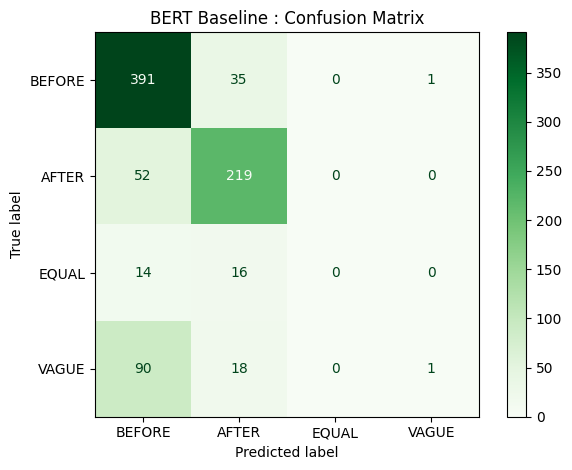

In [14]:
labels = ["BEFORE", "AFTER", "EQUAL", "VAGUE"]
cm = confusion_matrix(actual_labels,predictions,labels=[0, 1, 2, 3])
fig, ax = plt.subplots()
display = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
display.plot(ax=ax,cmap="Greens")
plt.title("BERT Baseline : Confusion Matrix")
plt.tight_layout()
plt.show()

## 4. Syntax-Guided Graph Transformer Evaluation

We evaluate our fine-tuned SGT model on the MATRES test set.



In [15]:
sgt_test_dataset = SGTDataset("processed_data/test.csv")
sgt_test_loader = DataLoader(sgt_test_dataset,batch_size=1,shuffle=False)

sgt_model = load_sgt_model(device)

print("Device:", device)
print("Test examples:", len(sgt_test_dataset))
print("Fine-tuned SGT model loaded successfully!")

Device: cuda
Test examples: 837
Fine-tuned SGT model loaded successfully!


In [16]:
sgt_actual_labels, sgt_predictions = evaluate_sgt(sgt_model,sgt_test_loader,device)

print("SGT evaluation completed!")
print("Total predictions:", len(sgt_predictions))

SGT evaluation completed!
Total predictions: 837


In [17]:
sgt_accuracy = accuracy_score(sgt_actual_labels, sgt_predictions)

print(f"Fine-tuned SGT Test Accuracy: {sgt_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        sgt_actual_labels,
        sgt_predictions,
        labels=[0, 1, 2, 3],
        target_names=["BEFORE", "AFTER", "EQUAL", "VAGUE"],
        zero_division=0
    )
)

Fine-tuned SGT Test Accuracy: 71.57%

Classification Report:
              precision    recall  f1-score   support

      BEFORE       0.80      0.83      0.82       427
       AFTER       0.77      0.77      0.77       271
       EQUAL       0.00      0.00      0.00        30
       VAGUE       0.28      0.31      0.30       109

    accuracy                           0.72       837
   macro avg       0.46      0.48      0.47       837
weighted avg       0.69      0.72      0.70       837



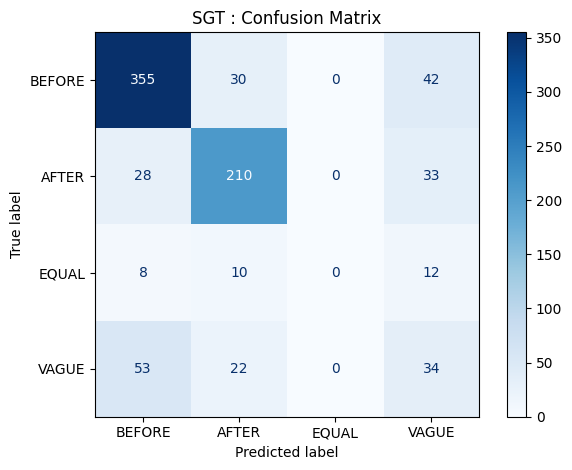

In [20]:
sgt_cm = confusion_matrix(sgt_actual_labels,sgt_predictions,labels=[0, 1, 2, 3])
fig, ax = plt.subplots()
sgt_display = ConfusionMatrixDisplay(confusion_matrix=sgt_cm,display_labels=["BEFORE", "AFTER", "EQUAL", "VAGUE"]
)
sgt_display.plot(ax=ax,cmap="Blues")
plt.title("SGT : Confusion Matrix")
plt.tight_layout()
plt.show()

## 5. BERT vs. SGT - Performance Comparison

We compare the two models on the same 837 MATRES test examples.The comparison includes accuracy, macro F1, and weighted F1.

In [27]:
comparison_df = pd.DataFrame({
    "Model": ["BERT Baseline", "Fine-tuned SGT"],
    "Accuracy": [
        accuracy_score(actual_labels, predictions),
        accuracy_score(sgt_actual_labels, sgt_predictions)
    ],
    "Macro F1": [
        f1_score(actual_labels, predictions, average="macro", labels=[0, 1, 2, 3], zero_division=0),
        f1_score(sgt_actual_labels, sgt_predictions, average="macro", labels=[0, 1, 2, 3], zero_division=0)
    ],
    "Weighted F1": [
        f1_score(actual_labels, predictions, average="weighted", labels=[0, 1, 2, 3], zero_division=0),
        f1_score(sgt_actual_labels, sgt_predictions, average="weighted", labels=[0, 1, 2, 3], zero_division=0)
    ]
})

comparison_df.round(3)

,Model,Accuracy,Macro F1,Weighted F1
0,BERT Baseline,0.730,0.401,0.666
1,Fine-tuned SGT,0.716,0.471,0.705


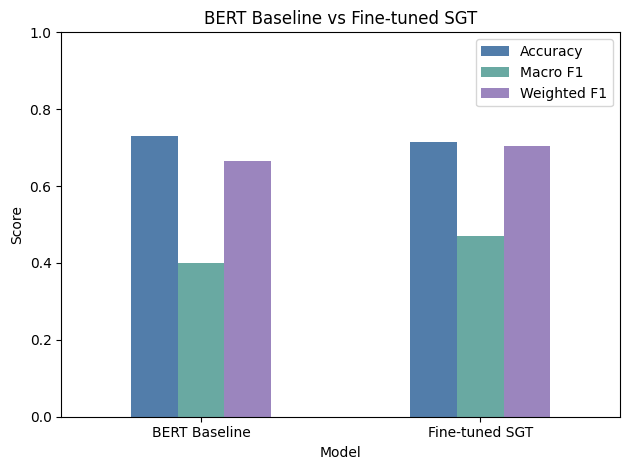

In [30]:
comparison_df.set_index("Model").plot(kind="bar",rot=0,color=["#527DAA", "#69A9A2", "#9B85BE"]
)
plt.title("BERT Baseline vs Fine-tuned SGT")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 6. Impact of Event Distance on Temporal Relation Classification

We compare BERT and SGT across different event distances to examine whether syntax-guided modeling helps with long-distance temporal relationships.

In [31]:
analysis_df = test_df.copy()
analysis_df["event_distance"] = abs(analysis_df["event1_index"] - analysis_df["event2_index"])
analysis_df.head()

,doc_id,text,event1,event2,event1_index,event2_index,relation,label,sent_diff,event_distance
0,WSJ_20130322_159,"The call , which happened as President Barack ...",happened,wrapped,4,9,BEFORE,0,0,5
1,WSJ_20130322_159,"The call , which happened as President Barack ...",happened,seemed,4,27,BEFORE,0,0,23
2,WSJ_20130322_159,"The call , which happened as President Barack ...",happened,yield,4,29,BEFORE,0,0,25
3,WSJ_20130322_159,"The call , which happened as President Barack ...",wrapped,seemed,9,27,VAGUE,3,0,18
4,WSJ_20130322_159,"The call , which happened as President Barack ...",wrapped,yield,9,29,VAGUE,3,0,20


In [32]:
def distance_category(distance):
    if distance < 10:
        return "Short"
    elif distance < 20:
        return "Medium"
    else:
        return "Long"

analysis_df["distance_group"] = analysis_df["event_distance"].apply(distance_category)
analysis_df[["event_distance", "distance_group"]].head()

,event_distance,distance_group
0,5,Short
1,23,Long
2,25,Long
3,18,Medium
4,20,Long


In [33]:
analysis_df["distance_group"].value_counts()

distance_group
Long      463
Medium    225
Short     149
Name: count, dtype: int64

In [34]:
analysis_df["bert_prediction"] = predictions
analysis_df["sgt_prediction"] = sgt_predictions
analysis_df[["label", "bert_prediction", "sgt_prediction", "distance_group"]].head()

,label,bert_prediction,sgt_prediction,distance_group
0,0,1,1,Short
1,0,0,0,Long
2,0,0,0,Long
3,3,0,0,Medium
4,3,0,0,Long


In [35]:
for group in ["Short","Medium","Long"]:
    subset = analysis_df[analysis_df["distance_group"] == group]
    accuracy = (subset["label"] == subset["bert_prediction"]).mean()
    print(group, ":", round(accuracy * 100, 2), "%")

Short : 76.51 %
Medium : 74.22 %
Long : 71.27 %


In [36]:
for group in ["Short","Medium","Long"]:
    subset = analysis_df[analysis_df["distance_group"] == group]
    accuracy = (subset["label"] == subset["sgt_prediction"]).mean()
    print(group, ":", round(accuracy * 100, 2), "%")

Short : 76.51 %
Medium : 73.33 %
Long : 69.11 %


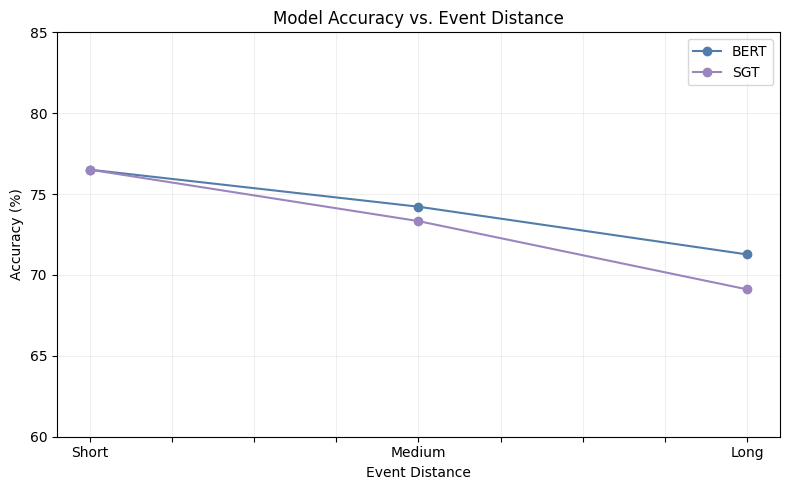

In [38]:
distance_results = pd.DataFrame({
    "Distance": ["Short", "Medium", "Long"],
    "BERT": [76.51, 74.22, 71.27],
    "SGT": [76.51, 73.33, 69.11]
})

distance_results.plot(
    x="Distance",
    y=["BERT", "SGT"],
    kind="line",
    marker="o",
    figsize=(8, 5),
    color=["#527DAA","#9B85BE"])

plt.title("Model Accuracy vs. Event Distance")
plt.xlabel("Event Distance")
plt.ylabel("Accuracy (%)")
plt.ylim(60, 85)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [39]:
for group in ["Short", "Medium", "Long"]:
    subset = analysis_df[analysis_df["distance_group"] == group]
    bert_f1 = f1_score(
        subset["label"],
        subset["bert_prediction"],
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0)
    sgt_f1 = f1_score(
        subset["label"],
        subset["sgt_prediction"],
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0)
    print(group)
    print("BERT Macro F1:", round(bert_f1, 3))
    print("SGT Macro F1:", round(sgt_f1, 3))
    print("--------------------")

Short
BERT Macro F1: 0.409
SGT Macro F1: 0.463
--------------------
Medium
BERT Macro F1: 0.4
SGT Macro F1: 0.47
--------------------
Long
BERT Macro F1: 0.396
SGT Macro F1: 0.465
--------------------


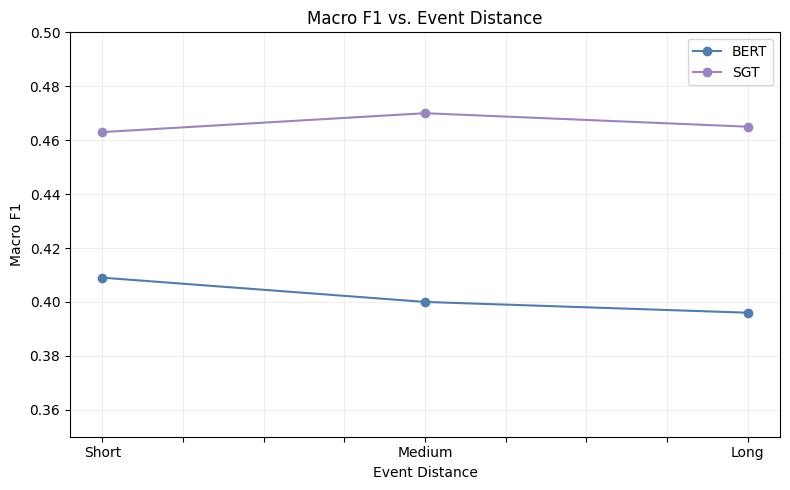

In [40]:
f1_results = pd.DataFrame({
    "Distance": ["Short", "Medium", "Long"],
    "BERT": [0.409, 0.400, 0.396],
    "SGT": [0.463, 0.470, 0.465]})

f1_results.plot(
    x="Distance",
    y=["BERT", "SGT"],
    kind="line",
    marker="o",
    figsize=(8, 5),
    color=["#527DAA", "#9B85BE"])

plt.title("Macro F1 vs. Event Distance")
plt.xlabel("Event Distance")
plt.ylabel("Macro F1")
plt.ylim(0.35, 0.50)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Dependency Path Analysis

We investigate how syntactic distance between event mentions affects temporal relation classification.

In [42]:
sample = test_df.iloc[0]
text = sample["text"]
event1_index = int(sample["event1_index"])
event2_index = int(sample["event2_index"])
doc = nlp(text)
event1_spacy = align_event_to_spacy(text,event1_index,doc)
event2_spacy = align_event_to_spacy(text,event2_index,doc)
print("Event 1:", doc[event1_spacy].text)
print("Event 2:", doc[event2_spacy].text)

Event 1: happened
Event 2: wrapped


In [43]:
edges,roots = build_dependency_graph(text)
path = get_dependency_path(edges,event1_spacy,event2_spacy)
print("Dependency path:", path)
print("Path length:", len(path) - 1)

Dependency path: [4, 9]
Path length: 1


In [44]:
path_words = [doc[i].text for i in path]
print("Dependency path:", " → ".join(path_words))

Dependency path: happened → wrapped


In [45]:
def calculate_dependency_distance(row):
    text = row["text"]
    doc = nlp(text)
    event1 = align_event_to_spacy(text, int(row["event1_index"]),doc)
    event2 = align_event_to_spacy(text, int(row["event2_index"]),doc)
    edges,roots = build_dependency_graph(text)
    path = get_dependency_path(edges,event1,event2)
    return len(path) - 1

In [46]:
analysis_df["dependency_distance"] = analysis_df.apply(calculate_dependency_distance,axis=1)
analysis_df[["event_distance", "dependency_distance"]].head()

,event_distance,dependency_distance
0,5,1
1,23,6
2,25,7
3,18,7
4,20,8


In [47]:
analysis_df["dependency_distance"].describe()

count    837.000000
mean       3.270012
std        2.253911
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       14.000000
Name: dependency_distance, dtype: float64

In [48]:
def dependency_category(distance):
    if distance <= 2:
        return "Short"
    elif distance <= 4:
        return "Medium"
    else:
        return "Long"

analysis_df["dependency_group"] = analysis_df["dependency_distance"].apply(dependency_category)
analysis_df["dependency_group"].value_counts()

dependency_group
Short     392
Medium    250
Long      195
Name: count, dtype: int64

In [50]:
for group in ["Short", "Medium", "Long"]:
    subset = analysis_df[analysis_df["dependency_group"] == group]

    bert_accuracy = (subset["label"] == subset["bert_prediction"]).mean()
    sgt_accuracy = (subset["label"] == subset["sgt_prediction"]).mean()

    print(group)
    print("BERT Accuracy:", round(bert_accuracy * 100, 2), "%")
    print("SGT Accuracy:", round(sgt_accuracy * 100, 2), "%")
    print("--------------------")

Short
BERT Accuracy: 77.04 %
SGT Accuracy: 72.96 %
--------------------
Medium
BERT Accuracy: 72.0 %
SGT Accuracy: 74.4 %
--------------------
Long
BERT Accuracy: 66.15 %
SGT Accuracy: 65.13 %
--------------------


In [51]:
for group in ["Short", "Medium", "Long"]:
    subset = analysis_df[analysis_df["dependency_group"] == group]

    bert_f1 = f1_score(
        subset["label"],
        subset["bert_prediction"],
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0)

    sgt_f1 = f1_score(
        subset["label"],
        subset["sgt_prediction"],
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0)

    print(group)
    print("BERT Macro F1:", round(bert_f1, 3))
    print("SGT Macro F1:", round(sgt_f1, 3))
    print("--------------------")

Short
BERT Macro F1: 0.425
SGT Macro F1: 0.46
--------------------
Medium
BERT Macro F1: 0.393
SGT Macro F1: 0.508
--------------------
Long
BERT Macro F1: 0.366
SGT Macro F1: 0.439
--------------------


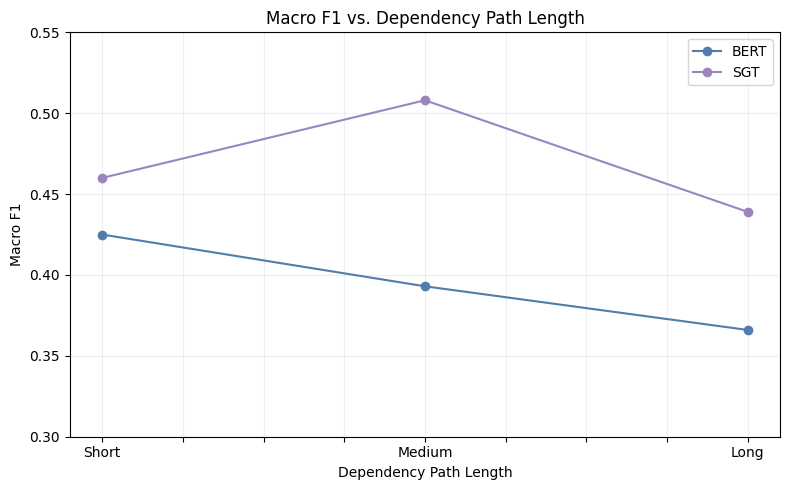

In [52]:
dependency_f1 = pd.DataFrame({
    "Distance": ["Short", "Medium", "Long"],
    "BERT": [0.425, 0.393, 0.366],
    "SGT": [0.460, 0.508, 0.439]})

dependency_f1.plot(
    x="Distance",
    y=["BERT", "SGT"],
    kind="line",
    marker="o",
    figsize=(8,5),
    color=["#527DAA", "#9B85BE"])

plt.title("Macro F1 vs. Dependency Path Length")
plt.xlabel("Dependency Path Length")
plt.ylabel("Macro F1")
plt.ylim(0.3, 0.55)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Dependency Graph Visualization

Dependency parsing represents grammatical relationships between words.



In [58]:
text = "John finished his work before he left."
doc = nlp(text)
options = {"compact": True,"distance": 120,"font": "Arial"}
displacy.render(doc, style="dep",jupyter=True,options=options)